# Taiwanese Bankruptcy Prediction — Combined Approach
*Augmented Decision — Final project*

**Question.** Can a handful of financial ratios and a readable decision tree tell us which firms are about to go bankrupt, well enough to support a real decision?

**Approach (combined).** *Variable selection* keeps the few ratios that carry signal, a *decision tree* turns them into simple rules and a bankruptcy probability, and a *cost-based threshold* turns that probability into an action.

**Roadmap**
1. **Problem formulation**: target, decision, metric, data, required preprocessing
2. Methods and choices
3. Tuning by cross-validation
4. Final evaluation on the test set
5. Recommendation and limitations

## 0. Setup
This part only needs `numpy`, `pandas` and `matplotlib`. The raw CSV's column names start with a space, so we strip them when loading.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREY, ORANGE = "#9aa5b1", "#c2571a"   # survived / bankrupt, used in every plot

DATA_PATH = "data/data.csv"
TARGET = "Bankrupt?"

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()   # raw names start with a space
X, y = df.drop(columns=TARGET), df[TARGET]

print(f"{len(df):,} firms × {X.shape[1]} features + target '{TARGET}'")
df.iloc[:5, :6]

6,819 firms × 95 features + target 'Bankrupt?'


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin
0,1,0.370594,0.424389,0.405750,0.601457,0.601457
1,1,0.464291,0.538214,0.516730,0.610235,0.610235
2,1,0.426071,0.499019,0.472295,0.601450,0.601364
3,1,0.399844,0.451265,0.457733,0.583541,0.583541
4,1,0.465022,0.538432,0.522298,0.598783,0.598783


# Part 1 — Problem formulation
The brief asks us to define **the prediction target, the decision to support and a suitable evaluation metric**, then to describe the data: **observations, variables, target distribution, missing values and required preprocessing**. We follow that order.

## 1.1 Prediction target
Each row is a **firm** listed in Taiwan, observed between 1999 and 2009. The target is

$$
Y = \begin{cases} 1 & \text{the firm went bankrupt} \\ 0 & \text{otherwise} \end{cases}
$$

where bankruptcy is defined by the business regulations of the Taiwan Stock Exchange. The features $x$ are 95 financial ratios computed from the firm's statements: profitability, leverage, liquidity, turnover, cash flow, growth and per-share figures.

We want more than a label: we estimate the **probability of bankruptcy** $\eta(x) = P(Y = 1 \mid X = x)$. The decision below needs a probability, because the two possible mistakes have very different costs.

> **Assumption (timing).** The ratios are known *before* the bankruptcy is observed. Otherwise a model built on them could not support a decision. The dataset has no date and no firm identifier, so we can neither check this nor split by time. We treat the 1999–2009 firms as a sample of the firms we will make decisions about.

## 1.2 The decision to support
**Who decides, and what?** A credit analyst (at a bank or an investment fund) monitors a portfolio of listed firms. For each firm, they choose an action $a \in \{0, 1\}$:
- $a = 0$: **no action**, the firm is treated as healthy;
- $a = 1$: **flag the firm for an in-depth review**, for example holding new credit until the review is done.

As in Lecture 1, we separate what is known at each moment:

| Moment | What happens |
|---|---|
| Before the action | The firm's latest financial ratios $x$ are available |
| At the decision | The analyst flags the firm or not: $a = \delta(x)$ |
| After the action | We observe whether the firm went bankrupt ($Y$) and record the loss |

**Loss table.** A review costs analyst time; a missed bankruptcy costs the money lent or invested. In units of one review:

| Action \ Outcome | Survives ($Y=0$) | Goes bankrupt ($Y=1$) |
|---|---|---|
| No flag ($a=0$) | 0 | $C_{FN} = 10$ (missed bankruptcy) |
| Flag ($a=1$) | $C_{FP} = 1$ (needless review) | 0 (bankruptcy caught) |

Only the *extra* cost of each mistake matters. Subtracting the same amount from a whole column (one outcome) changes neither action's ranking, so correct decisions can cost 0 without loss of generality.

> **Assumption (costs).** The ratio $C_{FN}/C_{FP} = 10$ is a modelling choice, not a market price: the data contains no costs. We test other ratios in 1.3.

**The Bayes decision rule.** For a firm with bankruptcy probability $p = \eta(x)$, the expected loss of each action is

$$
\rho(0 \mid x) = C_{FN}\, p, \qquad \rho(1 \mid x) = C_{FP}\,(1 - p).
$$

Flagging is the better action when $\rho(1 \mid x) \le \rho(0 \mid x)$, that is when

$$
p \;\ge\; t^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{11} \approx 0.091 .
$$

At a tie we flag, a tie-breaking convention we state explicitly (Lecture 1).

In [2]:
C_FP, C_FN = 1, 10                   # needless review, missed bankruptcy
THRESHOLD = C_FP / (C_FP + C_FN)     # Bayes threshold on P(bankrupt | x)
base_rate = y.mean()

print(f"Flag a firm when P(bankrupt | x) ≥ {THRESHOLD:.3f}")
print(f"Base rate of bankruptcy: {base_rate:.3f}"
      f" → a firm must look {THRESHOLD / base_rate:.1f}× riskier than average to be flagged")

Flag a firm when P(bankrupt | x) ≥ 0.091
Base rate of bankruptcy: 0.032 → a firm must look 2.8× riskier than average to be flagged


The plot below shows the two expected-loss lines. The firm should be flagged wherever the orange line ("flag") is below the grey one ("no flag").

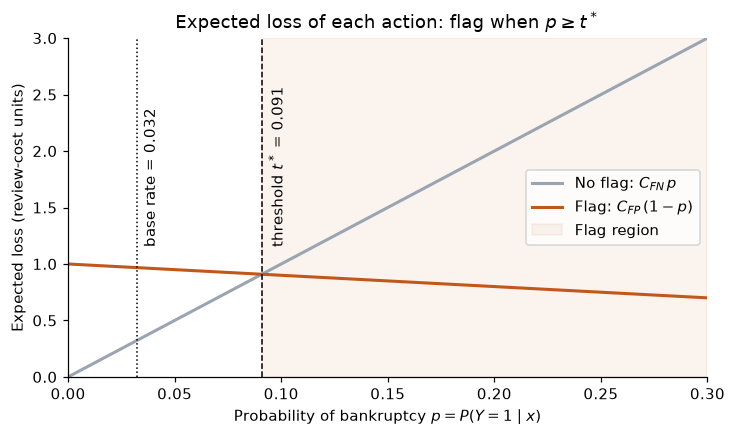

In [3]:
p = np.linspace(0, 0.3, 301)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(p, C_FN * p, color=GREY, lw=2, label=r"No flag: $C_{FN}\,p$")
ax.plot(p, C_FP * (1 - p), color=ORANGE, lw=2, label=r"Flag: $C_{FP}\,(1-p)$")
ax.axvspan(THRESHOLD, p.max(), color=ORANGE, alpha=0.07, label="Flag region")
ax.axvline(THRESHOLD, color="black", ls="--", lw=1)
ax.axvline(base_rate, color="black", ls=":", lw=1)
ax.text(THRESHOLD + 0.003, 1.15, f"threshold $t^*$ = {THRESHOLD:.3f}", rotation=90, va="bottom")
ax.text(base_rate + 0.003, 1.15, f"base rate = {base_rate:.3f}", rotation=90, va="bottom")
ax.set(xlim=(0, p.max()), ylim=(0, 3),
       xlabel=r"Probability of bankruptcy $p = P(Y=1 \mid x)$",
       ylabel="Expected loss (review-cost units)",
       title="Expected loss of each action: flag when $p \\geq t^*$")
ax.legend(loc="center right")
plt.show()

**Reading the plot.**
- At the base rate (3.2%), not flagging is cheaper: the expected loss is $10 \times 0.032 = 0.32$ against $1 \times 0.968 = 0.97$. **Without information, the best action is to flag nobody.**
- A firm should be flagged only if its probability exceeds 9.1%, about **3 times the average risk**. Finding these firms from their ratios is the model's job.

## 1.3 Evaluation metric
The metric must measure what the decision costs. We use the **average cost per firm**, the empirical risk of a decision rule $\delta$ on $n$ firms (Lecture 1):

$$
\hat R_n(\delta) = \frac{1}{n} \sum_{i=1}^{n} L\big(\delta(x_i), y_i\big) = \frac{C_{FP}\cdot FP + C_{FN}\cdot FN}{n}.
$$

Lower is better, and 0 is perfect. We use this same number at every stage: to **tune** (on validation folds), to **compare with the baseline**, and for the **final test**. That way every choice follows the decision, as the trees lecture recommends when costs are unequal.

Alongside it we report the **confusion matrix**, the **recall** (share of bankruptcies caught) and the **precision** (share of flags that were real bankruptcies). They are easier to explain to a decision maker.

**Why not accuracy?** We score three reference rules on the full dataset. The function `evaluate` will be reused for every model in the notebook.

In [4]:
def evaluate(y_true, flag):
    """Average cost per firm and the usual counts for a vector of decisions (1 = flag)."""
    y_true, flag = np.asarray(y_true), np.asarray(flag)
    tp = int(((flag == 1) & (y_true == 1)).sum())
    fp = int(((flag == 1) & (y_true == 0)).sum())
    fn = int(((flag == 0) & (y_true == 1)).sum())
    return {
        "cost per firm": (C_FP * fp + C_FN * fn) / len(y_true),
        "accuracy": float((flag == y_true).mean()),
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "flags": tp + fp,
        "missed bankruptcies": fn,
    }

reference_rules = {
    "Never flag (majority class)": np.zeros(len(y), dtype=int),
    "Flag every firm": np.ones(len(y), dtype=int),
    "Perfect foresight": y.to_numpy(),
}
pd.DataFrame.from_dict({name: evaluate(y, flag) for name, flag in reference_rules.items()},
                       orient="index").round(3)

,cost per firm,accuracy,recall,precision,flags,missed bankruptcies
Never flag (majority class),0.323,0.968,0.0,NaN,0,220
Flag every firm,0.968,0.032,1.0,0.032,6819,0
Perfect foresight,0.000,1.000,1.0,1.000,220,0


**Reading the table.**
- The majority-class rule scores **96.8% accuracy while catching zero bankruptcies**. Accuracy hides the only thing that matters here.
- In cost terms, never flagging costs **0.323 per firm** ($10 \times 3.2\%$). **This is the bar any model must beat.** Flagging every firm costs 0.968. We will recompute the baseline on the test set in Part 4.

**How sensitive is this to the cost ratio?** Lecture 1 showed that different costs can reverse a decision. With $C_{FP} = 1$, we vary $C_{FN}$:

In [5]:
ratios = np.array([2, 5, 10, 20, 30, 50])
sensitivity = pd.DataFrame({
    "C_FN / C_FP": ratios,
    "threshold t*": 1 / (1 + ratios),
    "cost: never flag": ratios * base_rate,
    "cost: flag every firm": 1 - base_rate,
})
sensitivity["cheaper reference rule"] = np.where(
    sensitivity["cost: never flag"] <= sensitivity["cost: flag every firm"], "never flag", "flag every firm")
sensitivity.round(3)

,C_FN / C_FP,threshold t*,cost: never flag,cost: flag every firm,cheaper reference rule
0,2,0.333,0.065,0.968,never flag
1,5,0.167,0.161,0.968,never flag
2,10,0.091,0.323,0.968,never flag
3,20,0.048,0.645,0.968,never flag
4,30,0.032,0.968,0.968,flag every firm
5,50,0.020,1.613,0.968,flag every firm


- As long as a missed bankruptcy costs less than about 30 reviews ($\approx 0.968 / 0.032$), the reference rule is "never flag".
- The threshold falls quickly as the ratio grows, from 0.33 at 2:1 to 0.02 at 50:1. **The cost ratio therefore drives how many firms get flagged.** We keep 10:1 as the main scenario and will repeat this sensitivity check with the final model.

## 1.4 Dataset description and citation

| | |
|---|---|
| Name | Taiwanese Bankruptcy Prediction |
| Source | Taiwan Economic Journal (TEJ), years 1999–2009 |
| Repository | UCI Machine Learning Repository, donated 27 June 2020 |
| DOI · licence | [10.24432/C5004D](https://doi.org/10.24432/C5004D) · CC BY 4.0 |
| Definition of bankruptcy | Business regulations of the Taiwan Stock Exchange |
| Original study | Liang, Lu, Tsai & Shih (2016), *European Journal of Operational Research*, 252(2), 561–572 |

**Citation.** *Taiwanese Bankruptcy Prediction* [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5004D

Which kinds of variables do we have?

In [6]:
kind = pd.cut(X.nunique(), bins=[0, 1, 2, np.inf], labels=["constant", "binary", "continuous"])

print(f"Observations: {len(df):,} firms   |   Features: {X.shape[1]}   |   Target: '{TARGET}'")
print("Storage types:", {str(t): n for t, n in X.dtypes.value_counts().items()})
print("Variable kinds:", kind.value_counts().to_dict())
print(f"Features entirely within [0, 1]: {(X.max() <= 1).sum()}   |   with values above 1: {(X.max() > 1).sum()}")
print("\nNon-continuous features:", kind[kind != "continuous"].to_dict())

Observations: 6,819 firms   |   Features: 95   |   Target: 'Bankrupt?'
Storage types: {'float64': 93, 'int64': 2}
Variable kinds: {'continuous': 93, 'constant': 1, 'binary': 1}
Features entirely within [0, 1]: 71   |   with values above 1: 24

Non-continuous features: {'Liability-Assets Flag': 'binary', 'Net Income Flag': 'constant'}


- All 95 features are numeric: 93 continuous ratios, 1 binary flag, 1 constant column.
- The data provider rescaled most ratios to $[0, 1]$, but 24 of them contain much larger values (see 1.6).

> **Note.** The variable dictionary in `data/README.md` (X1–X95) follows UCI's ordering, which does **not** match the column order of the CSV. We always refer to variables by their CSV column names.

## 1.5 Target distribution

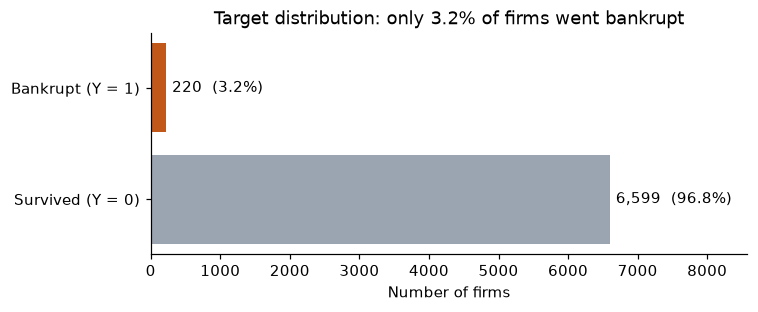

In [7]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(["Survived (Y = 0)", "Bankrupt (Y = 1)"], counts.values, color=[GREY, ORANGE])
ax.bar_label(bars, labels=[f"{n:,}  ({n / len(y):.1%})" for n in counts.values], padding=4)
ax.set(xlim=(0, counts.max() * 1.3), xlabel="Number of firms",
       title=f"Target distribution: only {base_rate:.1%} of firms went bankrupt")
plt.show()

The classes are heavily imbalanced: 220 bankrupt firms out of 6,819. How many bankruptcies will each evaluation step actually see?

In [8]:
n_test = round(0.2 * len(y))
n_train = len(y) - n_test
print(f"Bankrupt firms in a 20% test set:                  ≈ {base_rate * n_test:.0f} (out of {n_test:,} firms)")
print(f"Bankrupt firms in each validation fold (5-fold CV): ≈ {base_rate * n_train / 5:.0f} (out of {n_train / 5:,.0f} firms)")

Bankrupt firms in a 20% test set:                  ≈ 44 (out of 1,364 firms)
Bankrupt firms in each validation fold (5-fold CV): ≈ 35 (out of 1,091 firms)


With so few positives, every estimate will be noisy: one more or one fewer missed bankruptcy moves the cost per firm by about $10/1{,}364 \approx 0.007$ on the test set. This shapes our protocol:
1. **Stratify every split**, so that each part keeps 3.2% bankruptcies.
2. **Use 5-fold cross-validation rather than a single validation split**, so that every training firm serves once for validation.
3. **Keep the model small** (shallow tree, few variables). A deep tree would end up memorising individual bankrupt firms.
4. **Report the spread across folds**, not just the mean.
5. **No resampling** (SMOTE, undersampling). The asymmetry is already handled where it belongs: in the loss table and the threshold.

## 1.6 Missing values and data quality

In [9]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values: 0
Duplicate rows: 0


No missing values and no duplicate rows, so nothing needs to be imputed or removed. The data still has four quality issues worth knowing about.

### Constant and binary columns

In [10]:
print("Net Income Flag takes the values:", X["Net Income Flag"].unique())
pd.crosstab(X["Liability-Assets Flag"], y, margins=True,
            rownames=["Liability-Assets Flag"], colnames=["Bankrupt?"])

Net Income Flag takes the values: [1]


Bankrupt?,0,1,All
Liability-Assets Flag,,,
0,6597,214,6811
1,2,6,8
All,6599,220,6819


- **`Net Income Flag`** ("1 if net income was negative for the last two years") equals 1 for *every* firm. That is implausible and carries no information: **drop**.
- **`Liability-Assets Flag`** ("1 if total liabilities exceed total assets") is 1 for only 8 firms, but **6 of them went bankrupt (75% vs 3.1%)**. A rare but very strong signal: **keep**.

### Identical columns

In [11]:
cols = X.columns
duplicates = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:] if X[a].equals(X[b])]
duplicates

[('Current Liabilities/Liability', 'Current Liability to Liability'),
 ('Current Liabilities/Equity', 'Current Liability to Equity')]

Two pairs of columns are exact copies under different names. **Drop the second column of each pair.**

### Ratios that mix two scales
24 features have values far above 1, up to $10^{10}$. Looking closer, each of these columns mixes two scales:

In [12]:
large = X.columns[X.max() > 1]
is_large = X[large] > 1
scales = pd.DataFrame({
    "firms > 1": is_large.sum(),
    "share > 1": is_large.mean(),
    "P(bankrupt | > 1)": [y[is_large[c]].mean() for c in large],
    "P(bankrupt | ≤ 1)": [y[~is_large[c]].mean() for c in large],
}).sort_values("firms > 1", ascending=False)
scales.round(3)

,firms > 1,share > 1,P(bankrupt | > 1),P(bankrupt | ≤ 1)
Total Asset Growth Rate,6017,0.882,0.035,0.010
Cash Turnover Rate,4239,0.622,0.043,0.014
Research and development expense rate,4033,0.591,0.030,0.036
Inventory Turnover Rate (times),2946,0.432,0.040,0.026
Quick Asset Turnover Rate,2383,0.349,0.041,0.028
Operating Expense Rate,2282,0.335,0.029,0.034
Current Asset Turnover Rate,1234,0.181,0.043,0.030
Fixed Assets Turnover Frequency,1228,0.180,0.068,0.024
Interest-bearing debt interest rate,221,0.032,0.009,0.033
Long-term Liability to Current Assets,109,0.016,0.018,0.032


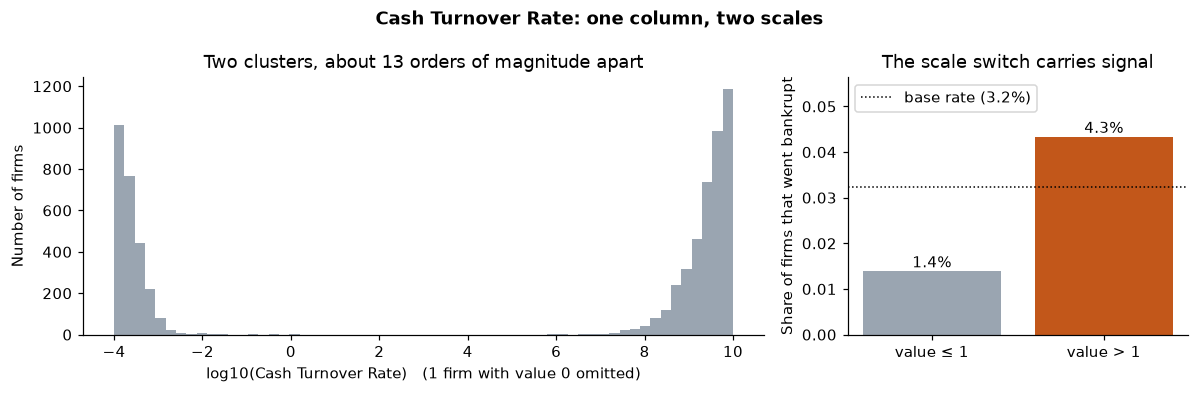

In [13]:
col = "Cash Turnover Rate"
v = X[col]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})

axes[0].hist(np.log10(v[v > 0]), bins=60, color=GREY)
axes[0].set(xlabel=f"log10({col})   (1 firm with value 0 omitted)", ylabel="Number of firms",
            title="Two clusters, about 13 orders of magnitude apart")

rates = [y[v <= 1].mean(), y[v > 1].mean()]
bars = axes[1].bar(["value ≤ 1", "value > 1"], rates, color=[GREY, ORANGE])
axes[1].bar_label(bars, labels=[f"{r:.1%}" for r in rates])
axes[1].axhline(base_rate, color="black", ls=":", lw=1, label=f"base rate ({base_rate:.1%})")
axes[1].set(ylim=(0, max(rates) * 1.3), ylabel="Share of firms that went bankrupt",
            title="The scale switch carries signal")
axes[1].legend(loc="upper left")

fig.suptitle(f"{col}: one column, two scales", fontweight="bold")
plt.tight_layout()
plt.show()

**What this means.** For some firms the ratio seems to be stored raw, for others already rescaled. This looks like an encoding artefact. We cannot recover a common scale, but we should **not delete or clip these values either**: in several columns the switch itself is informative. In `Cash Turnover Rate`, 4.3% of firms with large values went bankrupt against 1.4% of the others; in `Cash/Current Liability`, 33% against 3%. What we can rely on is the **order** of the values:
- **The decision tree needs nothing.** Its splits only depend on the order of values, so it can even split exactly at the scale switch.
- **LASSO needs care.** Standardising, the usual step before LASSO, would not help. Each column's mean and standard deviation are driven by the huge values. In `Quick Ratio`, for example, 9 firms around $10^9$ would squeeze the other 6,810 firms onto almost a single point. A **rank (quantile) transform** maps each column to $[0, 1]$ while keeping the order. Like any fitted step, it must be fitted on training data only.

### Highly correlated ratios
We use Spearman (rank) correlation, which the scale problem cannot distort.

In [14]:
rho = X.drop(columns="Net Income Flag").corr(method="spearman").abs()
upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().sort_values(ascending=False)

print(f"Pairs of features with |Spearman ρ| > 0.95: {(pairs > 0.95).sum()} (out of {len(pairs):,} pairs)")
pairs.head(12).round(3).rename("|ρ|").to_frame()

Pairs of features with |Spearman ρ| > 0.95: 50 (out of 4,371 pairs)


,,|ρ|
Current Liabilities/Equity,Current Liability to Equity,1.000
Debt ratio %,Net worth/Assets,1.000
Current Liabilities/Liability,Current Liability to Liability,1.000
Net worth/Assets,Equity to Liability,1.000
Debt ratio %,Equity to Liability,1.000
Operating Gross Margin,Gross Profit to Sales,1.000
Net Value Per Share (B),Net Value Per Share (A),1.000
Operating Profit Per Share (Yuan ¥),Operating profit/Paid-in capital,0.999
Net Value Per Share (A),Net Value Per Share (C),0.999
Net Value Per Share (B),Net Value Per Share (C),0.999


Many ratios are near-copies of each other. For example, `Debt ratio %` and `Net worth/Assets` are perfectly (inversely) rank-correlated, and the dataset has three versions of ROA and three of Net Value Per Share. This doesn't hurt prediction, but it matters for **variable selection** (Lectures 3–4):
- When two columns carry the same information, LASSO may keep either one, so the selected list can change from one sample to the next.
- A selected ratio is a **useful predictor**. That doesn't prove it matters more than its twin, and it isn't a **cause** of bankruptcy.

We will therefore measure **how stable the selection is** across resamples.

## 1.7 Required preprocessing

| Issue (evidence) | Action | Fitted on |
|---|---|---|
| Column names start with a space | Strip the names | — (done at load) |
| `Net Income Flag` is constant (1.6) | Drop | — |
| 2 pairs of identical columns (1.6) | Drop one column of each pair | — |
| No missing values, no duplicate rows (1.6) | Nothing to impute or remove | — |
| 24 ratios mix two scales, up to $10^{10}$ (1.6) | Rank (quantile) transform to $[0, 1]$ **before LASSO**. **Raw values for the tree**, so its rules stay readable | Training folds only |
| Only 3.2% bankruptcies (1.5) | Stratified 80/20 train/test split, stratified 5-fold CV, cost-based threshold, no resampling | — |
| Many near-duplicate ratios (1.6) | Keep them all, let selection choose, check selection stability | Training folds only |

We apply the three drops now.

In [15]:
to_drop = ["Net Income Flag"] + [b for _, b in duplicates]
X = X.drop(columns=to_drop)
print(f"Dropped {len(to_drop)} columns: {to_drop}")
print(f"Features kept: {X.shape[1]}")

Dropped 3 columns: ['Net Income Flag', 'Current Liability to Liability', 'Current Liability to Equity']
Features kept: 92


These drops look only at column contents, never at the target. Doing them once, before any split, therefore cannot leak information from the test set. Everything that is *fitted* (the rank transform, the variable selection, the tree) will be fitted inside each training fold, as the brief requires.

## 1.8 Summary of the problem

| | |
|---|---|
| **Target** | $Y = 1$ if the firm went bankrupt (220 of 6,819 firms, 3.2%) |
| **Decision** | Flag the firm for an in-depth review ($a = 1$) or not ($a = 0$) |
| **Loss** | Needless review $C_{FP} = 1$, missed bankruptcy $C_{FN} = 10$ (assumed, sensitivity checked) |
| **Decision rule** | Flag when $P(\text{bankrupt} \mid x) \ge 1/11 \approx 0.091$ |
| **Metric** | Average cost per firm (lower is better), with recall, precision and confusion matrix |
| **Bar to beat** | Never flag: $\approx 0.32$ per firm |
| **Data** | 92 numeric ratios after cleaning, no missing values |
| **Preprocessing** | Rank transform for LASSO (fitted in training folds), raw values for the tree |

**Next — Part 2: methods and choices.**

# Part 2 — Methods and choices
The brief asks us to **explain the approach** and to **justify the model, the preprocessing and the hyperparameters**. The whole method is one pipeline of four steps:

| Step | What it does | Learned from data? | Hyperparameters |
|---|---|---|---|
| 1. Rank transform + scaling | Puts every ratio on a common scale, robust to the $10^{10}$ values | Yes, training rows only | — |
| 2. Variable selection (LASSO) | Keeps the ratios with a non-zero L1-penalised logistic coefficient | Yes, training rows only | penalty $\lambda$ |
| 3. Decision tree | Learns if-then rules on the **raw** values of the selected ratios; each leaf gives a bankruptcy probability | Yes, training rows only | depth, minimum leaf size |
| 4. Decision | Flags a firm when its probability is $\ge t^* = 1/11$ | No: it follows from the loss table | — |

**Why a decision tree?**
- An analyst can read its rules, apply them and challenge them ("if the debt ratio is above … and the EPS below …, then review").
- It captures thresholds and interactions between ratios without us having to specify them.
- It only uses the *order* of values, so the two-scale problem of 1.6 does not affect it.
- Each leaf gives a probability (the share of bankrupt training firms in it), which is exactly what the decision rule needs.

**Why select variables before the tree?**
- With 92 ratios, many of them near-copies (1.6), the tree would pick among twins almost arbitrarily. The rules would be harder to explain and less stable.
- A short list is cheaper to collect and to monitor (Lecture 3: why applications need a variable shortlist).
- Whether selection also *improves prediction* is an empirical question. We answer it by comparing with a tree on all 92 ratios.

**Why LASSO rather than forward selection?** Both are course methods. LASSO has a single continuous tuning parameter, solves one convex problem instead of a greedy search, and handles 92 correlated candidates in one fit. Forward selection would need one refit per remaining candidate at every step, and a choice of classification model inside each fit.

## 2.1 Train/test split
We set aside 20% of the firms as the **test set**, stratified on $Y$ so that both parts keep 3.2% bankruptcies. The random seed is fixed once for reproducibility and never searched. **The test set is not used again until Part 4.**

Part 2 relies on scikit-learn:

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [17]:
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({"firms": [len(y_train), len(y_test)],
              "bankrupt": [y_train.sum(), y_test.sum()],
              "bankrupt rate": [y_train.mean(), y_test.mean()]},
             index=["train", "test"]).round(4)

,firms,bankrupt,bankrupt rate
train,5455,176,0.0323
test,1364,44,0.0323


All tuning happens inside the training set, with **stratified 5-fold cross-validation**: each training firm is used for validation exactly once.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pd.DataFrame([{"training firms": len(fit), "validation firms": len(val),
               "bankrupt in validation": int(y_train.iloc[val].sum())}
              for fit, val in cv.split(X_train, y_train)],
             index=[f"fold {k}" for k in range(1, 6)])

,training firms,validation firms,bankrupt in validation
fold 1,4364,1091,35
fold 2,4364,1091,35
fold 3,4364,1091,35
fold 4,4364,1091,35
fold 5,4364,1091,36


Each validation fold holds about 35 bankruptcies, as anticipated in 1.5.

## 2.2 Steps 1–2: rank transform and LASSO selection
**Objective.** Lecture 4's LASSO adds an L1 penalty to the fitting loss. The penalty sets some coefficients *exactly* to zero, and the variables with non-zero coefficients are the selected ones. Lecture 4 uses squared loss because its response is continuous. Ours is binary, so we keep the penalty and swap in the logistic loss (Lecture 2, appendix):

$$
(\hat b_0, \hat b) \in \arg\min_{b_0,\, b}\; \frac{1}{n}\sum_{i=1}^{n} \ell_{\log}\big(\sigma(b_0 + \tilde x_i^\top b),\; y_i\big) \;+\; \lambda \lVert b \rVert_1,
\qquad \hat S = \{\, j : \hat b_j \neq 0 \,\},
$$

where $\sigma(z) = 1/(1+e^{-z})$, $\ell_{\log}(q, y) = -y\log q - (1-y)\log(1-q)$ and $\tilde x$ is the transformed vector of ratios. As in Lecture 3, the intercept $b_0$ is not penalised. **A larger $\lambda$ means a stronger penalty and fewer ratios.**

scikit-learn expresses the penalty through $C = 1/(n\lambda)$. We pass $\lambda$ instead, so the same value means the same penalty on a fold ($n \approx 4{,}364$) and on the full training set ($n = 5{,}455$). The $\lambda$ chosen by cross-validation can then be reused unchanged for the final refit.

**Preprocessing inside the selector** (fitted on training rows only):
1. A **rank (quantile) transform** maps each ratio to $[0, 1]$ and keeps the order. This neutralises the two scales found in 1.6.
2. **Standardisation** (centre and scale with training rows, as in Lecture 3) makes the penalty treat every ratio the same way.

**Output.** The selector passes on the **raw** values of the selected ratios, so the tree's rules read in the ratios' own units.

In [19]:
class LassoSelector(BaseEstimator, TransformerMixin):
    """Keep the ratios with a non-zero L1-penalised logistic coefficient; pass on their raw values."""

    def __init__(self, lam=0.01):
        self.lam = lam

    def fit(self, X, y):
        self.lasso_ = make_pipeline(
            QuantileTransformer(),       # ranks -> [0, 1]: neutralises the two scales
            StandardScaler(),            # same scale for every ratio: a fair penalty
            LogisticRegression(l1_ratio=1, C=1 / (len(X) * self.lam),   # L1 penalty λ
                               solver="saga", max_iter=5000),
        ).fit(X, y)
        self.selected_ = list(X.columns[self.lasso_[-1].coef_.ravel() != 0])
        return self

    def transform(self, X):
        return X[self.selected_]         # raw values: the tree's rules stay readable

**Choosing the range of $\lambda$.** We fit the selector on the training set over a range of penalties and count the ratios it keeps: a regularisation path, as in Lecture 4. This uses training data only, and only to pick a sensible grid.

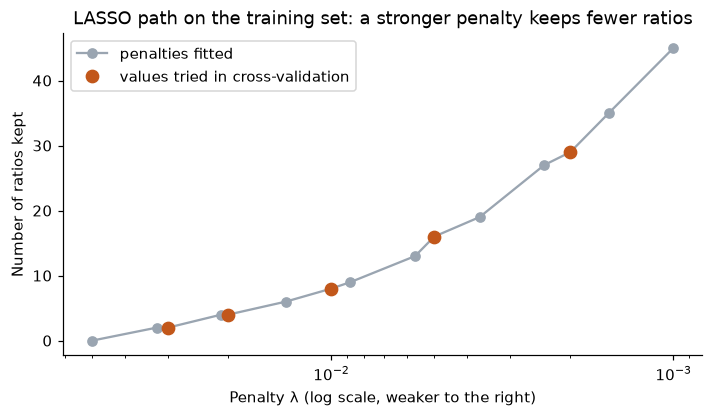

,0.030,0.020,0.010,0.005,0.002
ratios kept,2,4,8,16,29


In [20]:
LAMBDA_GRID = [0.03, 0.02, 0.01, 0.005, 0.002]
lam_path = np.unique(np.r_[np.logspace(-3, np.log10(0.05), 10), LAMBDA_GRID])
n_kept = pd.Series({lam: len(LassoSelector(lam).fit(X_train, y_train).selected_) for lam in lam_path})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(n_kept.index, n_kept.values, "o-", color=GREY, label="penalties fitted")
ax.plot(LAMBDA_GRID, n_kept.loc[LAMBDA_GRID], "o", color=ORANGE, ms=8, label="values tried in cross-validation")
ax.set(xscale="log", xlabel="Penalty λ (log scale, weaker to the right)", ylabel="Number of ratios kept",
       title="LASSO path on the training set: a stronger penalty keeps fewer ratios")
ax.invert_xaxis()
ax.legend()
plt.show()

n_kept.loc[LAMBDA_GRID].rename("ratios kept").to_frame().T

The grid runs from "a handful" (2 ratios at $\lambda = 0.03$) to about a third of the ratios (around 30 at $\lambda = 0.002$). Below that, LASSO keeps most ratios and selection loses its point. The baseline tree on all 92 ratios covers that end. For example, with $\lambda = 0.02$ the selector keeps:

In [21]:
LassoSelector(0.02).fit(X_train, y_train).selected_

['Non-industry income and expenditure/revenue',
 'Persistent EPS in the Last Four Seasons',
 'Total debt/Total net worth',
 'Borrowing dependency']

These ratios make financial sense: persistent earnings (EPS), non-operating income relative to revenue, leverage (debt to net worth) and dependence on borrowing. This is only an illustration on the full training set. The penalty is tuned by cross-validation in Part 3, and we will check how stable the selected list is.

> **Caveat.** The selection step uses a *linear* model, while the final model is a tree. LASSO keeps ratios whose rank moves (roughly) monotonically with the log-odds of bankruptcy. A ratio that only matters through a non-monotone effect, or through an interaction, could be dropped. The comparison with the tree on all ratios will show whether this costs us anything.

## 2.3 Step 3: the decision tree
We grow a CART tree with **Gini impurity** (trees lecture). The probability for a firm is the share of bankrupt training firms in the leaf it falls into, $\hat\eta(x)$. Two hyperparameters control the tree's size:
- **`max_depth`**, the number of successive questions. Depth 2 can already express an interaction (the lecture's two-question example), and depth 4 gives at most 16 leaves, still readable on one slide. Deeper trees are hard to read and, with only 176 bankrupt firms in training, tend to memorise them. Grid: {2, 3, 4, 5}.
- **`min_samples_leaf`**, the smallest number of firms allowed in a leaf. It matters twice here, because each leaf's probability is estimated from its own firms and then compared with $t^* = 0.091$:

In [22]:
leaf_sizes = np.array([10, 25, 50, 100])
pd.DataFrame({
    "firms in the leaf": leaf_sizes,
    "bankrupt firms needed to flag it": np.ceil(THRESHOLD * leaf_sizes).astype(int),
    "std. error of its probability near t*": np.sqrt(THRESHOLD * (1 - THRESHOLD) / leaf_sizes),
}).round(3)

,firms in the leaf,bankrupt firms needed to flag it,std. error of its probability near t*
0,10,1,0.091
1,25,3,0.057
2,50,5,0.041
3,100,10,0.029


With 10 firms per leaf, **a single bankrupt firm is enough to flag the whole leaf**, and the probability's standard error (0.091) is as large as the threshold itself. Such leaves memorise individual firms; the trees lecture warns that small leaves make probability estimates unstable. With 50–100 firms, a leaf is flagged only when several bankruptcies cluster in it. Grid: {10, 25, 50, 100}, and cross-validation decides.

**Two settings we deliberately leave at their defaults:**
- `criterion="gini"`, the impurity seen in the course.
- `class_weight=None`. The leaf shares must stay honest estimates of $P(Y = 1 \mid x)$ to be compared with $t^*$. Reweighting the classes would inflate them and count the cost asymmetry twice: once in the weights and once in the threshold.

## 2.4 Step 4: from probability to decision
The threshold is **not tuned**: $t^* = 1/11$ follows from the loss table (1.2). Tuning it on data would mix two jobs, estimating probabilities (the model's job) and valuing consequences (the decision maker's). It would also add noise, with only ~35 bankruptcies per fold. Instead, the scoring function applies the fixed threshold to every candidate on every validation fold:

In [23]:
def cost_per_firm(y_true, p_bankrupt):
    """Average cost per firm when flagging every firm with P(bankrupt | x) ≥ t*."""
    return evaluate(y_true, (p_bankrupt >= THRESHOLD).astype(int))["cost per firm"]

cost_scorer = make_scorer(cost_per_firm, response_method="predict_proba", greater_is_better=False)

scikit-learn maximises scores, so `greater_is_better=False` makes it report the **negative** cost. We flip the sign back when displaying results.

## 2.5 The full pipeline, the grid and the baselines

In [24]:
model = Pipeline([
    ("select", LassoSelector()),
    ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
param_grid = {
    "select__lam": LAMBDA_GRID,
    "tree__max_depth": [2, 3, 4, 5],
    "tree__min_samples_leaf": [10, 25, 50, 100],
}

n_candidates = int(np.prod([len(v) for v in param_grid.values()]))
print(f"{n_candidates} candidate settings × {cv.get_n_splits()} folds = {n_candidates * cv.get_n_splits()} fits")
model

80 candidate settings × 5 folds = 400 fits


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,lam,0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in

In Part 3, a grid search refits this **whole pipeline** (rank transform, scaling, LASSO and tree) on the training part of every fold and scores it on the validation part. Preprocessing and selection are therefore **fitted within each training split**, as the brief requires, and the test set is never seen.

**Baselines.** We compare against two references:
1. **Never flag**, the majority-class rule (1.3). It is the bar to beat.
2. **A tree on all 92 ratios**, tuned on the same tree grid. Its only difference from our model is the missing selection step, so the comparison isolates what selection brings.

In [25]:
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_grid = {"max_depth": param_grid["tree__max_depth"],
                 "min_samples_leaf": param_grid["tree__min_samples_leaf"]}

## 2.6 Summary of choices

| Choice | Value | Why |
|---|---|---|
| Test set | 20%, stratified, fixed seed | Untouched until Part 4; keeps 3.2% bankruptcies |
| Validation | Stratified 5-fold CV on the training set | ~35 bankruptcies per fold; every training firm validates once |
| Preprocessing | Rank transform + standardisation, inside the selector | Neutralises the two scales; fair penalty; refitted in every fold |
| Selection | L1-penalised logistic regression (LASSO), $\lambda \in \{0.03, 0.02, 0.01, 0.005, 0.002\}$ | Course method, sparse; keeps from 2 to about 30 ratios |
| Model | CART tree, Gini, on raw values | Readable rules, insensitive to scale, leaf probabilities |
| Depth | {2, 3, 4, 5} | Readable, captures interactions, limits overfitting |
| Leaf size | {10, 25, 50, 100} | Stable leaf probabilities |
| Decision | Flag if $\hat\eta(x) \ge 1/11$ | Bayes rule for the loss table, not tuned |
| Tuning criterion | Average cost per firm | The same metric as the final evaluation |
| Baselines | Never flag; tree on all 92 ratios | The bar to beat; isolates the effect of selection |

**Next — Part 3: tuning by cross-validation.**